# 单股票与五股票原型

依次练习数据检查、收益标签、20日动量、Pearson IC 与 Spearman RankIC。小股票池仅用于学习。

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the project root or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


依赖统一由 requirements.txt 安装。默认从冻结行情读取单股票和五股票原型；无行情时才联网。原始安装与卸载单元保存在本地 archive/originals。

In [2]:
import akshare as ak
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from src.data import get_stock_data
df = get_stock_data("000001")

In [4]:
df.head()

Out[0]: 
        date     open    close  ...  turnover        amount    code
0 2020-01-02  2607.73  2640.84  ...    0.0079  2.571196e+09  000001
1 2020-01-03  2651.38  2687.51  ...    0.0058  1.914496e+09  000001
2 2020-01-06  2661.92  2670.95  ...    0.0044  1.477930e+09  000001
3 2020-01-07  2679.98  2682.99  ...    0.0038  1.247047e+09  000001
4 2020-01-08  2660.41  2609.23  ...    0.0044  1.423609e+09  000001

[5 rows x 9 columns]


In [5]:
df.tail()

Out[0]: 
           date     open    close  ...  turnover       amount    code
1450 2025-12-25  2210.91  2213.92  ...    0.0028  633772600.0  000001
1451 2025-12-26  2213.92  2210.91  ...    0.0022  504079300.0  000001
1452 2025-12-29  2210.91  2213.92  ...    0.0033  749083000.0  000001
1453 2025-12-30  2209.41  2201.88  ...    0.0030  669409300.0  000001
1454 2025-12-31  2201.88  2191.34  ...    0.0030  675457400.0  000001

[5 rows x 9 columns]


In [6]:
df.shape

Out[0]: (1455, 9)


In [7]:
df.columns

Out[0]: 
Index(['date', 'open', 'close', 'high', 'low', 'volume', 'turnover', 'amount',
       'code'],
      dtype='str')


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1455 entries, 0 to 1454
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      1455 non-null   datetime64[ms]
 1   open      1455 non-null   float64       
 2   close     1455 non-null   float64       
 3   high      1455 non-null   float64       
 4   low       1455 non-null   float64       
 5   volume    1455 non-null   float64       
 6   turnover  1455 non-null   float64       
 7   amount    1455 non-null   float64       
 8   code      1455 non-null   str           
dtypes: datetime64[ms](1), float64(7), str(1)
memory usage: 111.1 KB


In [9]:
df.isna().sum()

Out[0]: 
date        0
open        0
close       0
high        0
low         0
volume      0
turnover    0
amount      0
code        0
dtype: int64


In [10]:
df.duplicated(subset=["date"]).sum()

Out[0]: np.int64(0)


In [11]:
print(df["date"].min())
print(df["date"].max())

2020-01-02 00:00:00
2025-12-31 00:00:00


In [12]:
def convert_code_tx(code):
    code = str(code).zfill(6)

    if code.startswith(("6", "9")):
        return "sh" + code
    else:
        return "sz" + code

In [13]:
print(convert_code_tx("000001"))
print(convert_code_tx("600519"))

sz000001
sh600519


In [14]:
from src.data import get_stock_data

In [15]:
sample = get_stock_data("000001")

In [16]:
sample.head()

Out[0]: 
        date     open    close  ...  turnover        amount    code
0 2020-01-02  2607.73  2640.84  ...    0.0079  2.571196e+09  000001
1 2020-01-03  2651.38  2687.51  ...    0.0058  1.914496e+09  000001
2 2020-01-06  2661.92  2670.95  ...    0.0044  1.477930e+09  000001
3 2020-01-07  2679.98  2682.99  ...    0.0038  1.247047e+09  000001
4 2020-01-08  2660.41  2609.23  ...    0.0044  1.423609e+09  000001

[5 rows x 9 columns]


In [17]:
sample[
    ["date", "code", "open", "close", "high", "low"]
].head()

Out[0]: 
        date    code     open    close     high      low
0 2020-01-02  000001  2607.73  2640.84  2652.89  2592.67
1 2020-01-03  000001  2651.38  2687.51  2707.08  2648.37
2 2020-01-06  000001  2661.92  2670.95  2711.60  2646.86
3 2020-01-07  000001  2679.98  2682.99  2702.56  2652.89
4 2020-01-08  000001  2660.41  2609.23  2667.94  2604.71


In [18]:
sample["daily_return"] = sample["close"].pct_change()

In [19]:
sample["momentum_20"] = sample["close"].pct_change(20)

In [20]:
sample["future_return_5"] = (
    sample["close"].shift(-5)
    / sample["close"]
    - 1
)

In [21]:
factor_sample = sample.dropna(
    subset=["momentum_20", "future_return_5"]
).copy()

In [22]:
test_codes = [
    "000001",
    "000002",
    "000063",
    "000100",
    "000157"
]

In [23]:
stock_data_list = []

In [24]:
for code in test_codes:
    try:
        df_temp = get_stock_data(code)
        if df_temp is not None:
           stock_data_list.append(df_temp)
    except Exception as e:
        print(code,"failed:",e)

In [25]:
len(stock_data_list)

Out[0]: 5


In [26]:
panel = pd.concat(
    stock_data_list,
    ignore_index=True
)

In [27]:
panel.head()

Out[0]: 
        date     open    close  ...  turnover        amount    code
0 2020-01-02  2607.73  2640.84  ...    0.0079  2.571196e+09  000001
1 2020-01-03  2651.38  2687.51  ...    0.0058  1.914496e+09  000001
2 2020-01-06  2661.92  2670.95  ...    0.0044  1.477930e+09  000001
3 2020-01-07  2679.98  2682.99  ...    0.0038  1.247047e+09  000001
4 2020-01-08  2660.41  2609.23  ...    0.0044  1.423609e+09  000001

[5 rows x 9 columns]


In [28]:
panel.tail()

Out[0]: 
           date    open   close  ...  turnover       amount    code
7268 2025-12-25  575.50  574.55  ...    0.0043  259459300.0  000157
7269 2025-12-26  573.59  581.25  ...    0.0068  409694700.0  000157
7270 2025-12-29  581.25  576.94  ...    0.0078  467204000.0  000157
7271 2025-12-30  575.02  580.29  ...    0.0080  485296000.0  000157
7272 2025-12-31  582.68  584.12  ...    0.0073  445348300.0  000157

[5 rows x 9 columns]


In [29]:
panel.shape

Out[0]: (7273, 9)


In [30]:
panel["code"].unique()

Out[0]: 
<ArrowStringArray>
['000001', '000002', '000063', '000100', '000157']
Length: 5, dtype: str


In [31]:
panel.groupby("code").size()

Out[0]: 
code
000001    1455
000002    1455
000063    1454
000100    1454
000157    1455
dtype: int64


In [32]:
panel = panel.sort_values(
    ["code", "date"]
).copy()

In [33]:
panel["momentum_20"] = (
    panel.groupby("code")["close"]
    .pct_change(20)
)

In [34]:
panel["future_return_5"] = (
    panel.groupby("code")["close"]
    .shift(-5)
    / panel["close"]
    - 1
)

In [35]:
panel_factor = panel.dropna(
    subset=["momentum_20", "future_return_5"]
).copy()

In [36]:
panel_factor.head()

Out[0]: 
         date     open    close  ...    code  momentum_20  future_return_5
20 2020-02-07  2299.13  2302.14  ...  000001    -0.128255         0.026810
21 2020-02-10  2285.58  2284.07  ...  000001    -0.150117         0.057341
22 2020-02-11  2299.13  2327.73  ...  000001    -0.128501         0.026515
23 2020-02-12  2327.73  2324.72  ...  000001    -0.133534         0.030434
24 2020-02-13  2315.69  2306.65  ...  000001    -0.115965         0.061349

[5 rows x 11 columns]


In [37]:
panel_factor.groupby("code").size()

Out[0]: 
code
000001    1430
000002    1430
000063    1429
000100    1429
000157    1430
dtype: int64


In [38]:
one_day = panel_factor["date"].iloc[0]
one_day_data = panel_factor[
    panel_factor["date"] == one_day
]
one_day_data[
    ["date", "code", "momentum_20", "future_return_5"]
]

Out[0]: 
           date    code  momentum_20  future_return_5
20   2020-02-07  000001    -0.128255         0.026810
1475 2020-02-07  000002    -0.134482         0.101333
2930 2020-02-07  000063     0.094679         0.013418
4384 2020-02-07  000100     0.215054        -0.020228
5838 2020-02-07  000157    -0.103762         0.039873


In [39]:
ic = one_day_data["momentum_20"].corr(
    one_day_data["future_return_5"]
)

In [40]:
ic

Out[0]: np.float64(-0.7959005273309454)


In [41]:
rank_ic = one_day_data["momentum_20"].corr(
    one_day_data["future_return_5"],
    method="spearman"
)

In [42]:
rank_ic

Out[0]: np.float64(-0.8999999999999998)


In [43]:
daily_ic = (
    panel_factor
    .groupby("date")
    .apply(
        lambda x: x["momentum_20"].corr(
            x["future_return_5"]
        )
    )
)

In [44]:
daily_rank_ic = (
    panel_factor
    .groupby("date")
    .apply(
        lambda x: x["momentum_20"].corr(
            x["future_return_5"],
            method="spearman"
        )
    )
)

In [45]:
daily_rank_ic

Out[0]: 
date
2020-02-07   -0.9
2020-02-10   -0.2
2020-02-11    0.6
2020-02-12    0.7
2020-02-13    0.7
             ... 
2025-12-18   -0.3
2025-12-19   -0.3
2025-12-22    0.4
2025-12-23    0.8
2025-12-24    0.6
Length: 1430, dtype: float64


In [46]:
print("Mean IC:", daily_ic.mean())
print("Mean RankIC:", daily_rank_ic.mean())

Mean IC: -0.019557515419763142
Mean RankIC: -0.01289573956417496


In [47]:
print("IC Std:", daily_ic.std())
print("RankIC Std:", daily_rank_ic.std())

IC Std: 0.5614203377983643
RankIC Std: 0.5279528165527076


In [48]:
icir = daily_ic.mean() / daily_ic.std()

rank_icir = (
    daily_rank_ic.mean()
    / daily_rank_ic.std()
)

print("ICIR:", icir)
print("Rank ICIR:", rank_icir)

ICIR: -0.03483578007960816
Rank ICIR: -0.0244259319391045


环境维护操作已移出可执行研究流程。

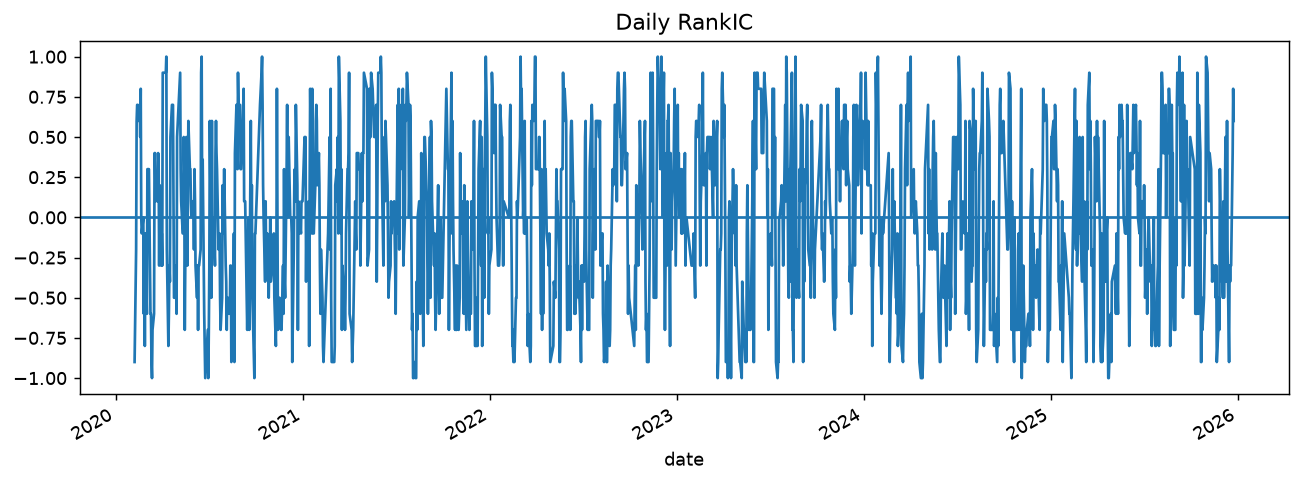

In [49]:
daily_rank_ic.plot(
    figsize=(12, 4),
    title="Daily RankIC"
)

plt.axhline(0)
plt.show()